# Blood Requirement Dataset - Beginner EDA

Is notebook me hum patient ke blood requirement dataset ka basic Exploratory Data Analysis (EDA) karenge.

**Target column:** `urgency_level` (Low / Medium / High / Critical)

## Step 1: Libraries import karo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style('whitegrid')

## Step 2: Data load karo

CSV file `blood_requirement_dataset.csv` isi folder me honi chahiye jahan ye notebook hai.

In [2]:
df = pd.read_csv('blood_requirement_dataset.csv')
df.head()

,patient_id,age,gender,weight_kg,blood_group,city,health_issue,hemoglobin_g_dl,platelet_count,systolic_bp,heart_rate,spo2_percent,active_bleeding,previous_transfusions,blood_component_needed,units_required,required_within_hours,urgency_level
0,P00001,13,Male,79.4,B+,Pune,Kidney disease (CKD),8.9,240206,101,95,95,0,0,Whole Blood,1,119,Low
1,P00002,50,Female,69.5,A-,Pune,Leukemia,6.1,60082,101,105,93,0,2,Packed RBC,2,10,Medium
2,P00003,58,Male,75.0,A+,Hyderabad,Dengue (low platelets),10.8,14619,102,77,99,0,1,Platelets,1,106,Low
3,P00004,21,Male,85.2,B+,Pune,Severe anemia,4.5,187413,83,132,91,0,1,Whole Blood,2,0,Critical
4,P00005,38,Female,94.9,O+,Lucknow,Postpartum hemorrhage,5.8,199900,101,118,89,1,0,Whole Blood,4,1,Critical


## Step 3: Basic jaankari

In [3]:
print('Rows, Columns:', df.shape)

Rows, Columns: (3000, 18)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   patient_id              3000 non-null   str    
 1   age                     3000 non-null   int64  
 2   gender                  3000 non-null   str    
 3   weight_kg               3000 non-null   float64
 4   blood_group             3000 non-null   str    
 5   city                    3000 non-null   str    
 6   health_issue            3000 non-null   str    
 7   hemoglobin_g_dl         3000 non-null   float64
 8   platelet_count          3000 non-null   int64  
 9   systolic_bp             3000 non-null   int64  
 10  heart_rate              3000 non-null   int64  
 11  spo2_percent            3000 non-null   int64  
 12  active_bleeding         3000 non-null   int64  
 13  previous_transfusions   3000 non-null   int64  
 14  blood_component_needed  3000 non-null   str    
 15

In [5]:
df.describe()

,age,weight_kg,hemoglobin_g_dl,platelet_count,systolic_bp,heart_rate,spo2_percent,active_bleeding,previous_transfusions,units_required,required_within_hours
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,33.708000,57.411933,8.092967,186053.219000,99.870333,99.051333,93.624667,0.225667,3.411333,2.454667,48.715333
std,22.264755,24.594040,2.252819,81508.590739,13.409255,12.066782,2.423857,0.418090,5.149529,1.527107,51.841156
min,1.000000,8.000000,4.000000,8535.000000,55.000000,55.000000,86.000000,0.000000,0.000000,0.000000,0.000000
25%,14.750000,42.775000,6.400000,135909.000000,90.000000,91.000000,92.000000,0.000000,0.000000,1.000000,5.000000
50%,31.000000,61.000000,7.800000,202888.000000,99.000000,100.000000,94.000000,0.000000,1.000000,2.000000,29.000000
75%,50.000000,77.825000,9.500000,245980.500000,109.000000,107.000000,95.000000,0.000000,2.000000,3.000000,88.000000
max,85.000000,95.000000,15.000000,398696.000000,159.000000,143.000000,100.000000,1.000000,20.000000,8.000000,168.000000


## Step 4: Missing values aur duplicates

In [6]:
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

patient_id                0
age                       0
gender                    0
weight_kg                 0
blood_group               0
city                      0
health_issue              0
hemoglobin_g_dl           0
platelet_count            0
systolic_bp               0
heart_rate                0
spo2_percent              0
active_bleeding           0
previous_transfusions     0
blood_component_needed    0
units_required            0
required_within_hours     0
urgency_level             0
dtype: int64

Duplicate rows: 0


## Step 5: Target column (urgency_level)

In [7]:
print(df['urgency_level'].value_counts())
print()
print((df['urgency_level'].value_counts(normalize=True) * 100).round(1))

urgency_level
Low         1147
Medium       706
High         679
Critical     468
Name: count, dtype: int64

urgency_level
Low         38.2
Medium      23.5
High        22.6
Critical    15.6
Name: proportion, dtype: float64


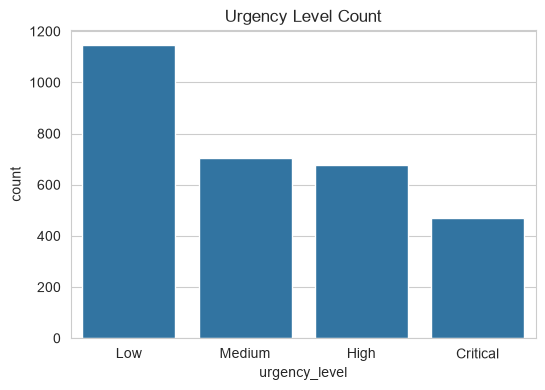

In [8]:
order = ['Low', 'Medium', 'High', 'Critical']

plt.figure(figsize=(6, 4))
sns.countplot(x='urgency_level', data=df, order=order)
plt.title('Urgency Level Count')
plt.show()

**Observation:** Classes thodi imbalanced hain (Low sabse zyada, Critical sabse kam).

## Step 6: Categorical columns

In [9]:
for col in ['gender', 'blood_group', 'health_issue', 'blood_component_needed', 'city']:
    print(col)
    print(df[col].value_counts())
    print('-' * 30)

gender
gender
Female    1595
Male      1405
Name: count, dtype: int64
------------------------------
blood_group
blood_group
O+     1059
B+      909
A+      671
AB+     194
O-       66
B-       59
A-       31
AB-      11
Name: count, dtype: int64
------------------------------
health_issue
health_issue
Severe anemia                      218
Leukemia                           214
Cancer (chemotherapy)              212
Road accident / trauma             209
Sickle cell crisis                 208
Burns                              206
Kidney disease (CKD)               203
Dengue (low platelets)             199
Thalassemia major                  196
Normal checkup / no major issue    194
GI bleeding                        194
Planned surgery                    190
Hemophilia                         190
Liver disease / cirrhosis          189
Postpartum hemorrhage              178
Name: count, dtype: int64
------------------------------
blood_component_needed
blood_component_needed
Packed R

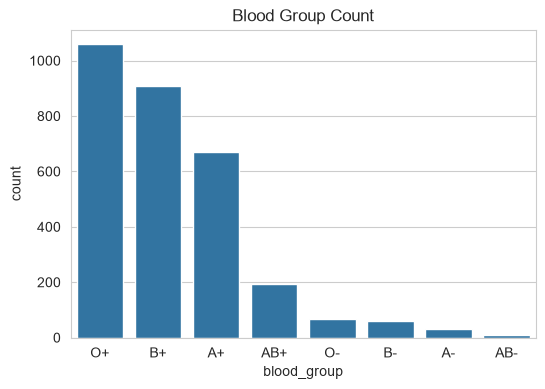

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x='blood_group', data=df, order=df['blood_group'].value_counts().index)
plt.title('Blood Group Count')
plt.show()

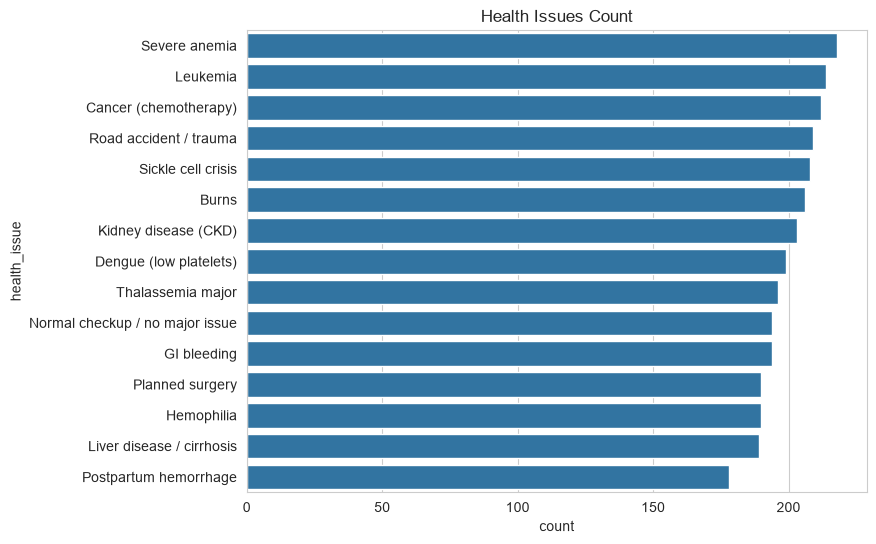

In [11]:
plt.figure(figsize=(8, 6))
sns.countplot(y='health_issue', data=df, order=df['health_issue'].value_counts().index)
plt.title('Health Issues Count')
plt.show()

## Step 7: Numerical columns ka distribution

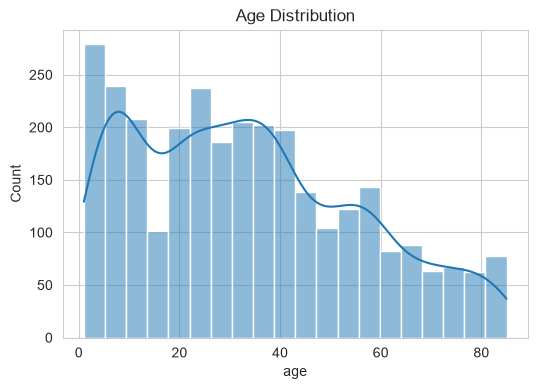

In [12]:
plt.figure(figsize=(6, 4))
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Age Distribution')
plt.show()

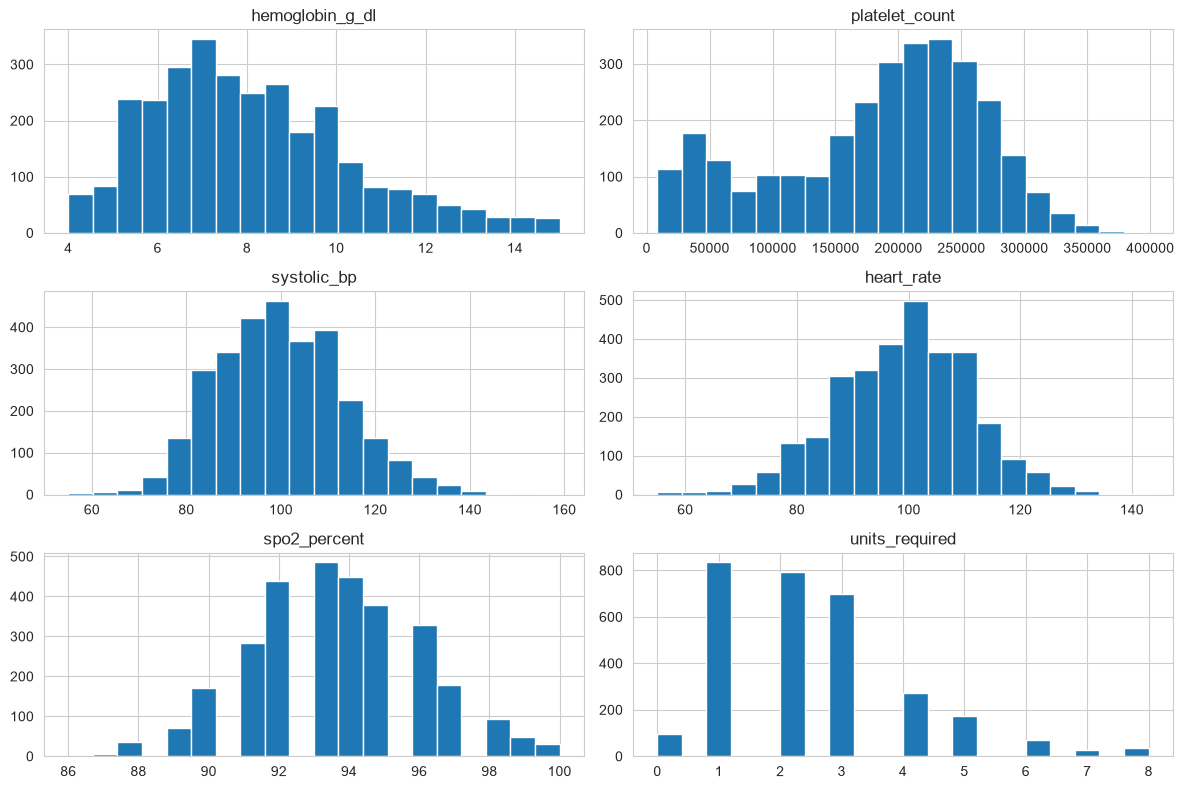

In [13]:
num_cols = ['hemoglobin_g_dl', 'platelet_count', 'systolic_bp', 'heart_rate', 'spo2_percent', 'units_required']

df[num_cols].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

## Step 8: Features vs Urgency

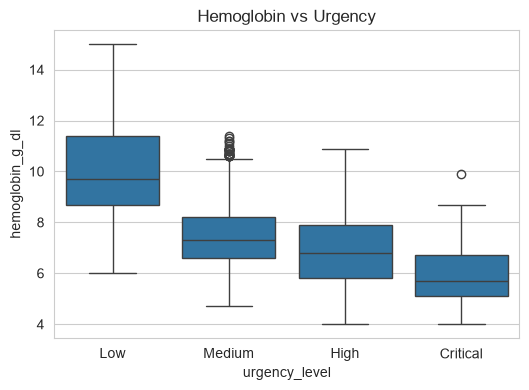

In [14]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='urgency_level', y='hemoglobin_g_dl', data=df, order=order)
plt.title('Hemoglobin vs Urgency')
plt.show()

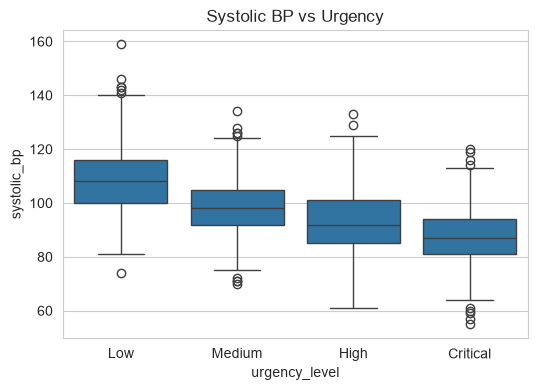

In [15]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='urgency_level', y='systolic_bp', data=df, order=order)
plt.title('Systolic BP vs Urgency')
plt.show()

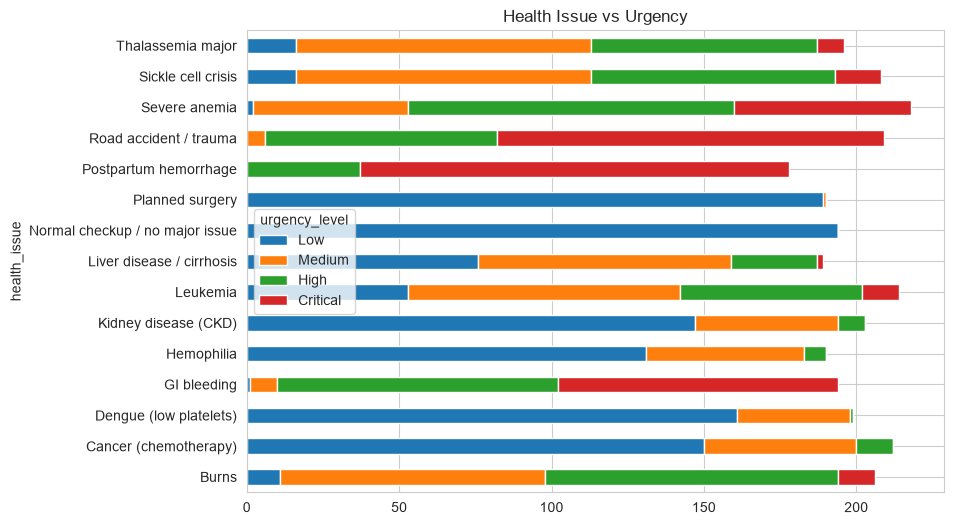

In [16]:
pd.crosstab(df['health_issue'], df['urgency_level'])[order].plot(kind='barh', stacked=True, figsize=(9, 6))
plt.title('Health Issue vs Urgency')
plt.show()

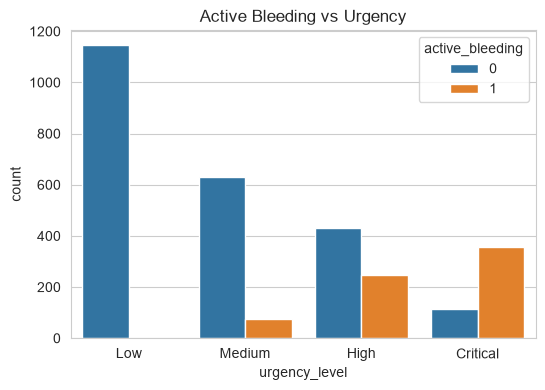

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(x='urgency_level', hue='active_bleeding', data=df, order=order)
plt.title('Active Bleeding vs Urgency')
plt.show()

In [18]:
df.groupby('urgency_level')[['hemoglobin_g_dl', 'systolic_bp', 'heart_rate', 'spo2_percent', 'units_required', 'required_within_hours']].mean().loc[order].round(1)

,hemoglobin_g_dl,systolic_bp,heart_rate,spo2_percent,units_required,required_within_hours
urgency_level,,,,,,
Low,10.0,108.9,90.8,95.0,1.8,106.7
Medium,7.5,99.0,100.9,93.3,2.2,28.1
High,6.9,93.8,104.0,92.8,2.9,5.1
Critical,5.9,87.8,109.2,91.8,3.8,1.0


## Step 9: Correlation heatmap

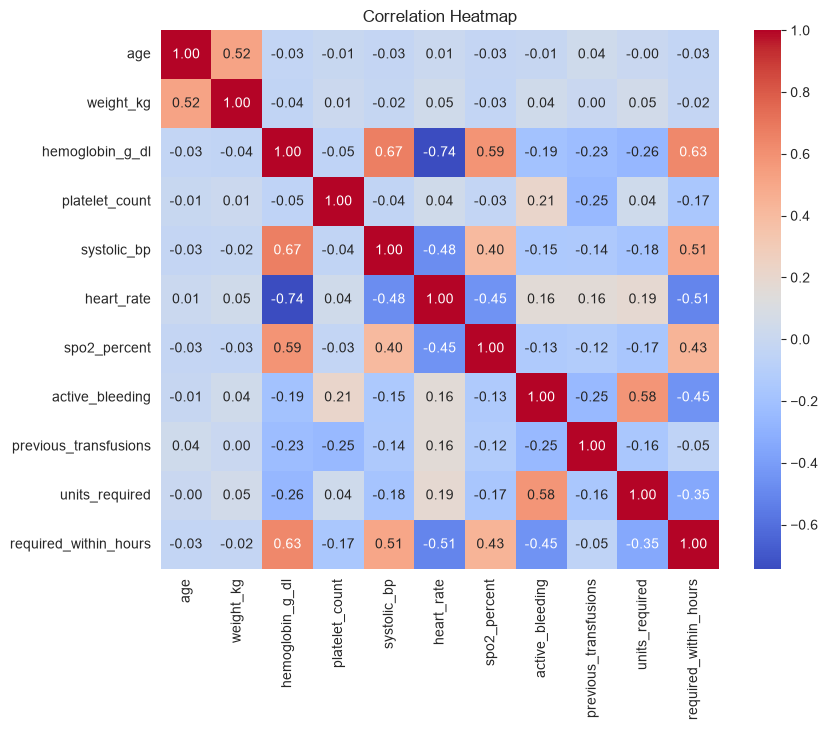

In [19]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## Step 10: Conclusions

- Dataset me **3000 rows, 18 columns** hain, koi missing value ya duplicate nahi hai.
- Urgency imbalanced hai: Low 38%, Medium 24%, High 23%, Critical 16%.
- Urgency badhne par **Hb, BP, SpO2 girte hain** aur heart rate badhta hai.
- **Postpartum hemorrhage, trauma aur GI bleeding** me Critical cases sabse zyada hain.
- **Active bleeding** wale patients me koi Low urgency nahi hai.
- Hemoglobin aur heart rate me strong negative correlation hai (-0.74).
- Age, weight aur city ka urgency par lagbhag koi asar nahi.

### Dhyan dene wali baatein
1. `units_required = 0` wali rows ("Normal checkup") ko check karna padega.
2. `required_within_hours` ko model me input mat dena (data leakage).
3. `patient_id` aur `city` model ke liye useful nahi hain.